In [1]:
import pandas as pd
import numpy as np
import sklearn
import xgboost
import torch

print("Air-Sense AI environment is ready!")
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

Air-Sense AI environment is ready!
PyTorch: 2.15.0+cpu
CUDA: False


# Air-Sense AI
## Air Quality Analysis and Forecasting Across Indian Cities

### Objective
- Analyze air quality data across multiple Indian cities.
- Forecast PM2.5 concentrations.
- Compare Random Forest, XGBoost and GRU models.
- Detect unusual pollution patterns.
- Evaluate model reliability when monitoring data is missing.M

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor, IsolationForest
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import xgboost as xgb
import torch

print("All Air-Sense AI libraries loaded successfully!")


All Air-Sense AI libraries loaded successfully!


In [5]:

from pathlib import Path

project_root = Path.cwd().parent

folders = ["data", "notebooks", "src", "models", "results"]

for folder in folders:
    path = project_root / folder
    print(f"{folder}: {'Available' if path.exists() else 'Missing'}")


data: Available
notebooks: Available
src: Available
models: Available
results: Available


In [6]:

from pathlib import Path

data_folder = project_root / "data"

files = list(data_folder.rglob("*"))

if not any(file.is_file() for file in files):
    print("No dataset files found yet.")
else:
    for file in files:
        if file.is_file():
            print(file.relative_to(project_root))


No dataset files found yet.


In [7]:

import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / "src"))

from feature_engineering import create_features

print("Feature engineering module imported successfully!")



Feature engineering module imported successfully!


In [8]:

from train_random_forest import train_random_forest

print("Random Forest training module imported successfully!")


Random Forest training module imported successfully!


In [9]:
from train_xgboost import train_xgboost

print("XGBoost training module imported successfully!")

XGBoost training module imported successfully!


In [10]:

from train_gru import AirSenseGRU, create_gru_model
import torch

model = create_gru_model(input_size=5)

# Test with a batch of 32 sequences,
# each containing 24 hours and 5 features.
sample_input = torch.randn(32, 24, 5)

output = model(sample_input)

print("GRU model created successfully!")
print("Input shape:", sample_input.shape)
print("Output shape:", output.shape)


GRU model created successfully!
Input shape: torch.Size([32, 24, 5])
Output shape: torch.Size([32, 1])


In [11]:

from model_evaluation import evaluate_model, compare_models

# Temporary test values only
actual = [50, 60, 70, 80, 90]
predicted = [52, 58, 72, 78, 88]

test_metrics = evaluate_model(
    actual,
    predicted,
    "Test Model"
)

print("Evaluation module working!")
print(test_metrics)


Evaluation module working!
{'Model': 'Test Model', 'MAE': 2.0, 'RMSE': np.float64(2.0), 'R2': 0.98}


In [13]:

import pandas as pd
import numpy as np

from anomaly_detection import detect_anomalies

# Temporary sample data for testing only
np.random.seed(42)

sample_data = pd.DataFrame({
    "pm25": np.random.normal(80, 10, 100),
    "temperature": np.random.normal(30, 3, 100),
    "humidity": np.random.normal(60, 8, 100),
    "wind_speed": np.random.normal(10, 2, 100)
})

# Add one artificial extreme value
sample_data.loc[99, "pm25"] = 300

result, anomaly_model = detect_anomalies(sample_data)

print("Anomaly detection module working!")
print("Detected anomalies:", result["anomaly"].sum())
print(result[result["anomaly"]])


Anomaly detection module working!
Detected anomalies: 2
         pm25  temperature   humidity  wind_speed  anomaly_label  anomaly
82   94.77894    26.787323  72.688135    5.752209             -1     True
99  300.00000    26.571089  65.037031   12.475633             -1     True


In [14]:
from train_gru import train_gru, AirSenseGRU

print("GRU training pipeline imported successfully!")

ImportError: cannot import name 'train_gru' from 'train_gru' (c:\Users\bhava\OneDrive\Desktop\AirSense-AI\src\train_gru.py)

In [15]:
import importlib
import train_gru

importlib.reload(train_gru)

print("train_gru function exists:", hasattr(train_gru, "train_gru"))
print("AirSenseGRU class exists:", hasattr(train_gru, "AirSenseGRU"))

train_gru function exists: True
AirSenseGRU class exists: True


In [16]:
from train_gru import train_gru, AirSenseGRU

print("GRU training pipeline imported successfully!")

GRU training pipeline imported successfully!


In [17]:

import pandas as pd
import numpy as np
from train_gru import train_gru

np.random.seed(42)

n = 300

sample_df = pd.DataFrame({
    "timestamp": pd.date_range(
        start="2025-01-01",
        periods=n,
        freq="h"
    ),
    "city": ["TestCity"] * n,
    "station_id": ["Station_1"] * n,
    "pm25": 80 + 15 * np.sin(np.arange(n) / 24)
            + np.random.normal(0, 5, n),
    "temperature": 30 + np.random.normal(0, 2, n),
    "humidity": 60 + np.random.normal(0, 5, n),
    "wind_speed": 10 + np.random.normal(0, 1, n)
})

model, metrics, results = train_gru(
    sample_df,
    lookback=24,
    epochs=5,
    batch_size=32
)

print("\nGRU training test completed!")
print("Metrics:", metrics)
print("\nPrediction preview:")
print(results.head())


Epoch 1/5, Loss: 6897.8675
Epoch 2/5, Loss: 6819.5631
Epoch 3/5, Loss: 6629.2256
Epoch 4/5, Loss: 6268.9085
Epoch 5/5, Loss: 6046.1611

GRU training test completed!
Metrics: {'MAE': 62.91182375101952, 'RMSE': np.float64(63.27514200295631), 'R2': -86.32741413867433}

Prediction preview:
            timestamp      city station_id  actual_pm25  predicted_pm25
0 2025-01-10 23:00:00  TestCity  Station_1    67.877080        5.921376
1 2025-01-11 00:00:00  TestCity  Station_1    70.748816        5.921615
2 2025-01-11 01:00:00  TestCity  Station_1    73.345312        5.920783
3 2025-01-11 02:00:00  TestCity  Station_1    74.662964        5.921250
4 2025-01-11 03:00:00  TestCity  Station_1    63.863296        5.921093


In [18]:
import importlib
import train_gru

importlib.reload(train_gru)

from train_gru import train_gru, AirSenseGRU

print("Updated GRU training pipeline loaded successfully!")

Updated GRU training pipeline loaded successfully!


In [19]:
import pandas as pd
import numpy as np
from train_gru import train_gru

np.random.seed(42)

n = 300

sample_df = pd.DataFrame({
    "timestamp": pd.date_range(
        start="2025-01-01",
        periods=n,
        freq="h"
    ),
    "city": ["TestCity"] * n,
    "station_id": ["Station_1"] * n,
    "pm25": 80 + 15 * np.sin(np.arange(n) / 24)
            + np.random.normal(0, 5, n),
    "temperature": 30 + np.random.normal(0, 2, n),
    "humidity": 60 + np.random.normal(0, 5, n),
    "wind_speed": 10 + np.random.normal(0, 1, n)
})

model, metrics, results = train_gru(
    sample_df,
    lookback=24,
    epochs=10,
    batch_size=32
)

print("\nGRU training test completed!")
print("Metrics:", metrics)
print("\nPrediction preview:")
print(results.head())

c:\Users\bhava\OneDrive\Desktop\AirSense-AI\.venv\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


Epoch 1/10, Loss: 0.9526
Epoch 2/10, Loss: 0.5550
Epoch 3/10, Loss: 0.3182
Epoch 4/10, Loss: 0.2724
Epoch 5/10, Loss: 0.2705
Epoch 6/10, Loss: 0.2704
Epoch 7/10, Loss: 0.2592
Epoch 8/10, Loss: 0.2492
Epoch 9/10, Loss: 0.2494
Epoch 10/10, Loss: 0.2443

GRU model and scalers saved successfully!

GRU training test completed!
Metrics: {'MAE': 4.363012622418426, 'RMSE': np.float64(5.6580313461891345), 'R2': 0.30174341222123613}

Prediction preview:
            timestamp      city station_id  actual_pm25  predicted_pm25
0 2025-01-10 23:00:00  TestCity  Station_1    67.877080       73.217209
1 2025-01-11 00:00:00  TestCity  Station_1    70.748816       72.996620
2 2025-01-11 01:00:00  TestCity  Station_1    73.345312       72.072868
3 2025-01-11 02:00:00  TestCity  Station_1    74.662964       71.159927
4 2025-01-11 03:00:00  TestCity  Station_1    63.863296       71.264603


In [20]:
import importlib
import train_gru

importlib.reload(train_gru)

from train_gru import train_gru, AirSenseGRU

print("GRU module updated successfully!")

GRU module updated successfully!


In [21]:
import pandas as pd
import numpy as np
from train_gru import train_gru

np.random.seed(42)

n = 300

sample_df = pd.DataFrame({
    "timestamp": pd.date_range(
        start="2025-01-01",
        periods=n,
        freq="h"
    ),
    "city": ["TestCity"] * n,
    "station_id": ["Station_1"] * n,
    "pm25": 80 + 15 * np.sin(np.arange(n) / 24)
            + np.random.normal(0, 5, n),
    "temperature": 30 + np.random.normal(0, 2, n),
    "humidity": 60 + np.random.normal(0, 5, n),
    "wind_speed": 10 + np.random.normal(0, 1, n)
})

model, metrics, results = train_gru(
    sample_df,
    lookback=24,
    epochs=10,
    batch_size=32
)

print("\nTraining completed!")
print("Metrics:", metrics)
print("\nPredictions:")
print(results.head())

Epoch 1/10, Loss: 0.9306
Epoch 2/10, Loss: 0.5318
Epoch 3/10, Loss: 0.3040
Epoch 4/10, Loss: 0.2858
Epoch 5/10, Loss: 0.2782
Epoch 6/10, Loss: 0.2821
Epoch 7/10, Loss: 0.2539
Epoch 8/10, Loss: 0.2435
Epoch 9/10, Loss: 0.2396
Epoch 10/10, Loss: 0.2479

GRU model and scalers saved successfully!

Training completed!
Metrics: {'MAE': 4.408469417421216, 'RMSE': np.float64(5.7229087528307705), 'R2': 0.28563858898689587}

Predictions:
            timestamp      city station_id  actual_pm25  predicted_pm25
0 2025-01-10 23:00:00  TestCity  Station_1    67.877080       73.440331
1 2025-01-11 00:00:00  TestCity  Station_1    70.748816       73.111229
2 2025-01-11 01:00:00  TestCity  Station_1    73.345312       72.187286
3 2025-01-11 02:00:00  TestCity  Station_1    74.662964       71.276978
4 2025-01-11 03:00:00  TestCity  Station_1    63.863296       71.344833


In [22]:

import pandas as pd
from pathlib import Path

data_path = Path.cwd().parent / "data" / "pm25_quality_checked.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nCountries:")
print(df["country"].value_counts(dropna=False))

print("\nCities:")
print(df["city"].value_counts(dropna=False))

print("\nQuality flags:")
print(df["quality_flag"].value_counts(dropna=False))

print("\nMissing values:")
print(df.isnull().sum())


FileNotFoundError: [Errno 2] No such file or directory: 'c:\\Users\\bhava\\OneDrive\\Desktop\\AirSense-AI\\data\\pm25_quality_checked.csv'

In [23]:
from pathlib import Path

print("Current notebook location:")
print(Path.cwd())

print("\nFiles in the project folder:")
project_folder = Path.cwd().parent
for item in project_folder.iterdir():
    print(item.name)

print("\nFiles in the data folder:")
data_folder = project_folder / "data"

if data_folder.exists():
    for item in data_folder.iterdir():
        print(item.name)
else:
    print("The data folder does not exist.")

Current notebook location:
c:\Users\bhava\OneDrive\Desktop\AirSense-AI\notebooks

Files in the project folder:
.git
.gitignore
.venv
data
models
notebooks
pm25_historical_6months.csv
pm25_quality_checked.csv
README.md
requirements.txt
results
src

Files in the data folder:


In [24]:
import pandas as pd
from pathlib import Path

project_folder = Path.cwd().parent
data_path = project_folder / "pm25_quality_checked.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nCountries:")
print(df["country"].value_counts(dropna=False))

print("\nCities:")
print(df["city"].value_counts(dropna=False))

print("\nQuality flags:")
print(df["quality_flag"].value_counts(dropna=False))

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (66073, 14)

Columns:
['sensor_id', 'location_id', 'country', 'city', 'latitude', 'longitude', 'datetime_utc', 'datetime_end_utc', 'parameter', 'value', 'unit', 'original_value', 'value_clean', 'quality_flag']

Countries:
country
United States     21325
Japan             19689
Germany           13343
France             7527
United Kingdom     4189
Name: count, dtype: int64

Cities:
city
Houston-Sugar Land-Baytown    21325
                              19689
Tower Hamlets                  4189
Spremberg                      3994
München                        3806
SAINT-ÉTIENNE                  3790
SAINT-NAZAIRE-LE-DÉSERT        3737
Hagen                          3543
Stuttgart                      2000
Name: count, dtype: int64

Quality flags:
quality_flag
Valid                          65673
Invalid negative value           312
Missing                           87
Review unusually high value        1
Name: count, dtype: int64

Missing values:
sensor_id             0
l

In [25]:
print("Quality flag counts:")
print(df["quality_flag"].value_counts(dropna=False))

print("\nParameter counts:")
print(df["parameter"].value_counts(dropna=False))

print("\nMissing value counts:")
print(df[["value", "original_value", "value_clean"]].isnull().sum())

print("\nClean PM2.5 statistics:")
print(df["value_clean"].describe())

print("\nRows with missing clean values:")
print(df[df["value_clean"].isna()][
    ["country", "city", "datetime_utc", "value",
     "original_value", "value_clean", "quality_flag"]
].head(10))

Quality flag counts:
quality_flag
Valid                          65673
Invalid negative value           312
Missing                           87
Review unusually high value        1
Name: count, dtype: int64

Parameter counts:
parameter
pm25    66073
Name: count, dtype: int64

Missing value counts:
value              87
original_value     87
value_clean       399
dtype: int64

Clean PM2.5 statistics:
count    65674.000000
mean         8.419151
std          6.594142
min          0.000000
25%          5.000000
50%          7.470000
75%         11.000000
max        985.000000
Name: value_clean, dtype: float64

Rows with missing clean values:
            country                        city               datetime_utc  \
4402  United States  Houston-Sugar Land-Baytown  2026-05-01 02:00:00+00:00   
4410  United States  Houston-Sugar Land-Baytown  2026-05-01 10:00:00+00:00   
4411  United States  Houston-Sugar Land-Baytown  2026-05-01 11:00:00+00:00   
4414  United States  Houston-Sugar Land-B

In [26]:
import pandas as pd
from pathlib import Path

# Work on a copy; keep the original dataset unchanged
model_df = df.copy()

# Keep only valid readings for the initial forecasting dataset
model_df = model_df[model_df["quality_flag"] == "Valid"].copy()

# Standardize column names for our ML code
model_df["timestamp"] = pd.to_datetime(
    model_df["datetime_utc"], utc=True
)

model_df["station_id"] = (
    model_df["sensor_id"].astype(str)
    + "_"
    + model_df["location_id"].astype(str)
)

model_df["pm25"] = pd.to_numeric(
    model_df["value_clean"], errors="coerce"
)

# Keep blank city names as Unknown
model_df["city"] = model_df["city"].fillna("Unknown")
model_df["city"] = model_df["city"].replace("", "Unknown")

# Remove any rows without a usable PM2.5 value or timestamp
model_df = model_df.dropna(subset=["pm25", "timestamp"])

# Sort by station and time
model_df = model_df.sort_values(
    ["station_id", "timestamp"]
).reset_index(drop=True)

print("Prepared dataset shape:", model_df.shape)
print("\nColumns:")
print(model_df.columns.tolist())

print("\nCountry counts:")
print(model_df["country"].value_counts())

print("\nNumber of stations:", model_df["station_id"].nunique())

print("\nPM2.5 summary:")
print(model_df["pm25"].describe())

Prepared dataset shape: (65673, 17)

Columns:
['sensor_id', 'location_id', 'country', 'city', 'latitude', 'longitude', 'datetime_utc', 'datetime_end_utc', 'parameter', 'value', 'unit', 'original_value', 'value_clean', 'quality_flag', 'timestamp', 'station_id', 'pm25']

Country counts:
country
United States     21060
Japan             19689
Germany           13343
France             7527
United Kingdom     4054
Name: count, dtype: int64

Number of stations: 17

PM2.5 summary:
count    65673.000000
mean         8.404280
std          5.381526
min          0.000000
25%          5.000000
50%          7.470000
75%         11.000000
max        174.000000
Name: pm25, dtype: float64


In [27]:
# Calculate time difference between consecutive readings at each station
model_df["time_gap_hours"] = (
    model_df.groupby("station_id")["timestamp"]
    .diff()
    .dt.total_seconds() / 3600
)

print("Time gap distribution (hours):")
print(model_df["time_gap_hours"].value_counts().head(15))

print("\nTime gap summary:")
print(model_df["time_gap_hours"].describe())

print("\nHourly continuity by station:")
for station, group in model_df.groupby("station_id"):
    gaps = group["time_gap_hours"].dropna()
    hourly_pct = (gaps == 1).mean() * 100

    print(
        station,
        "| Readings:", len(group),
        "| Exactly 1-hour gaps:", round(hourly_pct, 2), "%"
    )

Time gap distribution (hours):
time_gap_hours
1.0     62787
2.0      1410
3.0      1177
4.0       118
5.0        45
6.0        43
8.0        15
9.0         6
7.0         6
12.0        4
15.0        3
10.0        3
38.0        2
23.0        2
20.0        2
Name: count, dtype: int64

Time gap summary:
count    65656.000000
mean         1.106753
std          2.110917
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max        289.000000
Name: time_gap_hours, dtype: float64

Hourly continuity by station:
11770_2935 | Readings: 3994 | Exactly 1-hour gaps: 95.04 %
12915957_151 | Readings: 4054 | Exactly 1-hour gaps: 97.41 %
1300251_2936 | Readings: 2000 | Exactly 1-hour gaps: 96.3 %
2031_186 | Readings: 4294 | Exactly 1-hour gaps: 98.74 %
2071327_164 | Readings: 4324 | Exactly 1-hour gaps: 98.27 %
2071333_173 | Readings: 3739 | Exactly 1-hour gaps: 97.46 %
2071339_187 | Readings: 4303 | Exactly 1-hour gaps: 98.05 %
268_162 | Readings: 4400 | Exactly 1-h

In [28]:
# Calculate time difference between consecutive readings at each station
model_df["time_gap_hours"] = (
    model_df.groupby("station_id")["timestamp"]
    .diff()
    .dt.total_seconds() / 3600
)

print("Time gap distribution (hours):")
print(model_df["time_gap_hours"].value_counts().head(15))

print("\nTime gap summary:")
print(model_df["time_gap_hours"].describe())

print("\nHourly continuity by station:")
for station, group in model_df.groupby("station_id"):
    gaps = group["time_gap_hours"].dropna()
    hourly_pct = (gaps == 1).mean() * 100

    print(
        station,
        "| Readings:", len(group),
        "| Exactly 1-hour gaps:", round(hourly_pct, 2), "%"
    )

Time gap distribution (hours):
time_gap_hours
1.0     62787
2.0      1410
3.0      1177
4.0       118
5.0        45
6.0        43
8.0        15
9.0         6
7.0         6
12.0        4
15.0        3
10.0        3
38.0        2
23.0        2
20.0        2
Name: count, dtype: int64

Time gap summary:
count    65656.000000
mean         1.106753
std          2.110917
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max        289.000000
Name: time_gap_hours, dtype: float64

Hourly continuity by station:
11770_2935 | Readings: 3994 | Exactly 1-hour gaps: 95.04 %
12915957_151 | Readings: 4054 | Exactly 1-hour gaps: 97.41 %
1300251_2936 | Readings: 2000 | Exactly 1-hour gaps: 96.3 %
2031_186 | Readings: 4294 | Exactly 1-hour gaps: 98.74 %
2071327_164 | Readings: 4324 | Exactly 1-hour gaps: 98.27 %
2071333_173 | Readings: 3739 | Exactly 1-hour gaps: 97.46 %
2071339_187 | Readings: 4303 | Exactly 1-hour gaps: 98.05 %
268_162 | Readings: 4400 | Exactly 1-h

In [29]:
# Count gaps longer than one hour
gap_counts = (
    model_df[model_df["time_gap_hours"] > 1]
    .groupby("time_gap_hours")
    .size()
    .sort_index()
)

print("Gaps longer than one hour:")
print(gap_counts)

print("\nTotal gaps longer than one hour:")
print(gap_counts.sum())

print("\nPercentage of consecutive readings with exactly one-hour gaps:")
valid_gaps = model_df["time_gap_hours"].dropna()

hourly_percentage = (
    (valid_gaps == 1).mean() * 100
)

print(round(hourly_percentage, 2), "%")

# Station-level summary
station_summary = (
    model_df.groupby(["station_id", "country"])
    .agg(
        readings=("pm25", "count"),
        first_reading=("timestamp", "min"),
        last_reading=("timestamp", "max")
    )
    .reset_index()
)

print("\nStation summary:")
print(station_summary.to_string(index=False))

Gaps longer than one hour:
time_gap_hours
2.0      1410
3.0      1177
4.0       118
5.0        45
6.0        43
7.0         6
8.0        15
9.0         6
10.0        3
11.0        1
12.0        4
13.0        2
14.0        2
15.0        3
16.0        2
17.0        2
19.0        2
20.0        2
21.0        2
23.0        2
28.0        2
29.0        1
31.0        2
35.0        1
36.0        1
38.0        2
43.0        1
53.0        1
60.0        1
79.0        1
84.0        1
89.0        1
101.0       1
130.0       2
181.0       1
201.0       1
202.0       1
289.0       1
dtype: int64

Total gaps longer than one hour:
2869

Percentage of consecutive readings with exactly one-hour gaps:
95.63 %

Station summary:
     station_id        country  readings             first_reading              last_reading
     11770_2935        Germany      3994 2026-05-01 00:00:00+00:00 2026-10-31 22:00:00+00:00
   12915957_151 United Kingdom      4054 2026-05-01 00:00:00+00:00 2026-10-31 22:00:00+00:00
   13

In [30]:
# Overall hourly continuity
gaps = model_df["time_gap_hours"].dropna()

print("TOTAL READINGS:", len(model_df))
print("TOTAL STATIONS:", model_df["station_id"].nunique())
print("CONSECUTIVE HOURLY GAPS:", (gaps == 1).sum())
print("GAPS LONGER THAN ONE HOUR:", (gaps > 1).sum())
print("EXPECTED HOURS MISSING:", (gaps[gaps > 1] - 1).sum())
print("HOURLY CONTINUITY (%):", round((gaps == 1).mean() * 100, 2))

# Compact station-level report
station_report = (
    model_df.groupby(["station_id", "country"])
    .agg(
        readings=("pm25", "count"),
        hourly_continuity_pct=("time_gap_hours",
            lambda x: round((x.dropna() == 1).mean() * 100, 2))
    )
    .reset_index()
)

print("\nSTATION REPORT:")
print(station_report.to_string(index=False))

TOTAL READINGS: 65673
TOTAL STATIONS: 17
CONSECUTIVE HOURLY GAPS: 62787
GAPS LONGER THAN ONE HOUR: 2869
EXPECTED HOURS MISSING: 7009.0
HOURLY CONTINUITY (%): 95.63

STATION REPORT:
     station_id        country  readings  hourly_continuity_pct
     11770_2935        Germany      3994                  95.04
   12915957_151 United Kingdom      4054                  97.41
   1300251_2936        Germany      2000                  96.30
       2031_186  United States      4294                  98.74
    2071327_164  United States      4324                  98.27
    2071333_173  United States      3739                  97.46
    2071339_187  United States      4303                  98.05
        268_162  United States      4400                  99.82
   5078830_2916        Germany      3543                  93.05
      5614_2676         France      3737                  90.74
6515679_1214470          Japan      3992                  94.84
6515883_1214468          Japan      3877           

In [31]:
# Create time-aware hourly lag features

def create_hourly_features(data):
    result = data.copy()

    result = result.sort_values(
        ["station_id", "timestamp"]
    ).copy()

    result = result.set_index("timestamp")

    lag_hours = [1, 2, 3, 6, 12, 24]

    for lag in lag_hours:
        result[f"pm25_lag_{lag}"] = (
            result.groupby("station_id")["pm25"]
            .transform(
                lambda series: series.reindex(
                    pd.date_range(
                        series.index.min(),
                        series.index.max(),
                        freq="h",
                        tz="UTC"
                    )
                ).shift(lag).reindex(series.index)
            )
        )

    result = result.reset_index()

    result["hour"] = result["timestamp"].dt.hour
    result["day_of_week"] = result["timestamp"].dt.dayofweek
    result["month"] = result["timestamp"].dt.month

    return result


feature_df = create_hourly_features(model_df)

print("Feature dataset shape:", feature_df.shape)

print("\nLag feature availability:")
for lag in [1, 2, 3, 6, 12, 24]:
    print(
        f"Lag {lag}:",
        feature_df[f"pm25_lag_{lag}"].notna().sum(),
        "available readings"
    )

print("\nSample:")
print(
    feature_df[
        ["station_id", "timestamp", "pm25",
         "pm25_lag_1", "pm25_lag_2", "pm25_lag_24"]
    ].head(10).to_string(index=False)
)

Feature dataset shape: (65673, 27)

Lag feature availability:
Lag 1: 62787 available readings
Lag 2: 61714 available readings
Lag 3: 61574 available readings
Lag 6: 61301 available readings
Lag 12: 61018 available readings
Lag 24: 62401 available readings

Sample:
station_id                 timestamp  pm25  pm25_lag_1  pm25_lag_2  pm25_lag_24
11770_2935 2026-05-01 00:00:00+00:00  11.0         NaN         NaN          NaN
11770_2935 2026-05-01 01:00:00+00:00   8.0        11.0         NaN          NaN
11770_2935 2026-05-01 02:00:00+00:00   8.0         8.0        11.0          NaN
11770_2935 2026-05-01 03:00:00+00:00   7.0         8.0         8.0          NaN
11770_2935 2026-05-01 04:00:00+00:00   7.0         7.0         8.0          NaN
11770_2935 2026-05-01 05:00:00+00:00   8.0         7.0         7.0          NaN
11770_2935 2026-05-01 06:00:00+00:00  15.0         8.0         7.0          NaN
11770_2935 2026-05-01 07:00:00+00:00  19.0        15.0         8.0          NaN
11770_2935 2026

C:\Users\bhava\AppData\Local\Temp\ipykernel_19000\870142902.py:32: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  result["day_of_week"] = result["timestamp"].dt.dayofweek


In [32]:
# Create the one-hour-ahead target using exact timestamps

def create_forecasting_target(data):
    result = data.copy()

    result = result.sort_values(
        ["station_id", "timestamp"]
    ).copy()

    result["target_pm25"] = float("nan")

    for station, group in result.groupby("station_id"):
        future_values = group.set_index("timestamp")["pm25"]

        target_times = group["timestamp"] + pd.Timedelta(hours=1)

        result.loc[group.index, "target_pm25"] = (
            target_times.map(future_values).values
        )

    # Calendar features
    result["hour"] = result["timestamp"].dt.hour
    result["day_of_week"] = result["timestamp"].dt.day_of_week
    result["month"] = result["timestamp"].dt.month

    return result


forecast_df = create_forecasting_target(feature_df)

print("Forecast dataset shape:", forecast_df.shape)

print("\nAvailable one-hour-ahead targets:")
print(forecast_df["target_pm25"].notna().sum())

print("\nMissing targets:")
print(forecast_df["target_pm25"].isna().sum())

print("\nSample:")
print(
    forecast_df[
        ["station_id", "timestamp", "pm25",
         "pm25_lag_1", "target_pm25"]
    ].head(10).to_string(index=False)
)

Forecast dataset shape: (65673, 28)

Available one-hour-ahead targets:
62787

Missing targets:
2886

Sample:
station_id                 timestamp  pm25  pm25_lag_1  target_pm25
11770_2935 2026-05-01 00:00:00+00:00  11.0         NaN          8.0
11770_2935 2026-05-01 01:00:00+00:00   8.0        11.0          8.0
11770_2935 2026-05-01 02:00:00+00:00   8.0         8.0          7.0
11770_2935 2026-05-01 03:00:00+00:00   7.0         8.0          7.0
11770_2935 2026-05-01 04:00:00+00:00   7.0         7.0          8.0
11770_2935 2026-05-01 05:00:00+00:00   8.0         7.0         15.0
11770_2935 2026-05-01 06:00:00+00:00  15.0         8.0         19.0
11770_2935 2026-05-01 07:00:00+00:00  19.0        15.0         11.0
11770_2935 2026-05-01 08:00:00+00:00  11.0        19.0          6.0
11770_2935 2026-05-01 09:00:00+00:00   6.0        11.0          3.0


In [33]:
from sklearn.model_selection import train_test_split

# Select model input features
features = [
    "pm25_lag_1",
    "pm25_lag_2",
    "pm25_lag_3",
    "pm25_lag_6",
    "pm25_lag_12",
    "pm25_lag_24",
    "hour",
    "day_of_week",
    "month"
]

# Keep rows with complete inputs and a valid future target
ml_df = forecast_df.dropna(
    subset=features + ["target_pm25"]
).copy()

# Use a global chronological cutoff
cutoff = ml_df["timestamp"].quantile(0.8)

train_df = ml_df[ml_df["timestamp"] <= cutoff].copy()
test_df = ml_df[ml_df["timestamp"] > cutoff].copy()

X_train = train_df[features]
y_train = train_df["target_pm25"]

X_test = test_df[features]
y_test = test_df["target_pm25"]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training ends:", train_df["timestamp"].max())
print("Testing starts:", test_df["timestamp"].min())
print("Number of input features:", len(features))

Training rows: 37922
Testing rows: 9470
Training ends: 2026-09-24 05:00:00+00:00
Testing starts: 2026-09-24 06:00:00+00:00
Number of input features: 9


In [34]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from pathlib import Path
import joblib
import numpy as np

# Initialize Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)

# Train
print("Training Random Forest...")
rf_model.fit(X_train, y_train)

# Predict
rf_predictions = rf_model.predict(X_test)

# Evaluate
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("\nRANDOM FOREST RESULTS")
print("---------------------")
print("MAE:", round(rf_mae, 4))
print("RMSE:", round(rf_rmse, 4))
print("R2 Score:", round(rf_r2, 4))

# Save model in the project's models folder
project_folder = Path.cwd().parent
models_folder = project_folder / "models"
models_folder.mkdir(exist_ok=True)

joblib.dump(
    rf_model,
    models_folder / "random_forest.pkl"
)

print("\nModel saved successfully!")

Training Random Forest...

RANDOM FOREST RESULTS
---------------------
MAE: 2.3112
RMSE: 3.252
R2 Score: 0.5614

Model saved successfully!


RANDOM FOREST FEATURE IMPORTANCE
    Feature  Importance
 pm25_lag_1    0.727636
 pm25_lag_2    0.058210
pm25_lag_12    0.049484
 pm25_lag_3    0.039615
pm25_lag_24    0.035547
 pm25_lag_6    0.034349
       hour    0.029743
day_of_week    0.013036
      month    0.012380


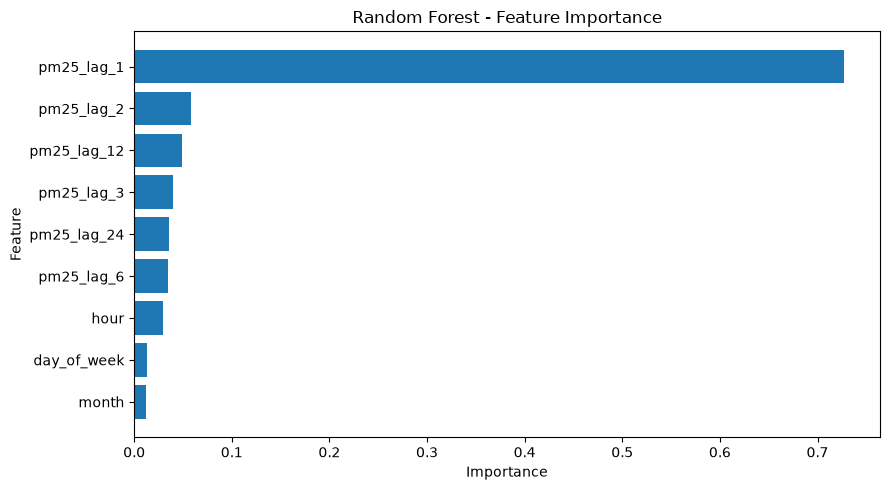

In [35]:
import pandas as pd

# Calculate feature importance
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": rf_model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print("RANDOM FOREST FEATURE IMPORTANCE")
print(importance_df.to_string(index=False))

# Plot feature importance
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest - Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [36]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import joblib
from pathlib import Path

# Initialize XGBoost
xgb_model = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective="reg:squarederror",
    n_jobs=-1
)

# Train
print("Training XGBoost...")
xgb_model.fit(X_train, y_train)

# Predict
xgb_predictions = xgb_model.predict(X_test)

# Evaluate
xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
xgb_r2 = r2_score(y_test, xgb_predictions)

print("\nXGBOOST RESULTS")
print("---------------------")
print("MAE:", round(xgb_mae, 4))
print("RMSE:", round(xgb_rmse, 4))
print("R2 Score:", round(xgb_r2, 4))

# Save model
project_folder = Path.cwd().parent
models_folder = project_folder / "models"
models_folder.mkdir(exist_ok=True)

joblib.dump(xgb_model, models_folder / "xgboost.pkl")

print("\nXGBoost model saved successfully!")

Training XGBoost...

XGBOOST RESULTS
---------------------
MAE: 2.2981
RMSE: 3.3121
R2 Score: 0.545

XGBoost model saved successfully!


In [37]:
import pandas as pd
from pathlib import Path

comparison = pd.DataFrame([
    {
        "Model": "Random Forest",
        "MAE": rf_mae,
        "RMSE": rf_rmse,
        "R2": rf_r2
    },
    {
        "Model": "XGBoost",
        "MAE": xgb_mae,
        "RMSE": xgb_rmse,
        "R2": xgb_r2
    }
])

comparison = comparison.sort_values("RMSE")

print(comparison.to_string(index=False))

# Save comparison
project_folder = Path.cwd().parent
results_folder = project_folder / "results"
results_folder.mkdir(exist_ok=True)

comparison.to_csv(
    results_folder / "model_comparison.csv",
    index=False
)

print("\nComparison saved to results/model_comparison.csv")

        Model      MAE     RMSE       R2
Random Forest 2.311162 3.251983 0.561380
      XGBoost 2.298139 3.312103 0.545012

Comparison saved to results/model_comparison.csv


In [38]:
import sys
from pathlib import Path

project_folder = Path.cwd().parent
sys.path.append(str(project_folder / "src"))

from train_gru import train_gru

print("Updated GRU module imported successfully!")

Updated GRU module imported successfully!


In [39]:
# Use the same chronological cutoff as Random Forest and XGBoost
gru_cutoff = train_df["timestamp"].max()

gru_model, gru_metrics, gru_results = train_gru(
    df=model_df,
    lookback=24,
    epochs=30,
    batch_size=32,
    cutoff=gru_cutoff
)

print("\nGRU RESULTS")
print("--------------------")
print("MAE:", round(gru_metrics["MAE"], 4))
print("RMSE:", round(gru_metrics["RMSE"], 4))
print("R2 Score:", round(gru_metrics["R2"], 4))

TypeError: train_gru() got an unexpected keyword argument 'cutoff'

In [40]:
import importlib
import train_gru as gru_module

importlib.reload(gru_module)

train_gru = gru_module.train_gru

print("GRU module reloaded successfully!")

GRU module reloaded successfully!


In [41]:
gru_cutoff = train_df["timestamp"].max()

gru_model, gru_metrics, gru_results = train_gru(
    df=model_df,
    lookback=24,
    epochs=30,
    batch_size=32,
    cutoff=gru_cutoff
)

print("\nGRU RESULTS")
print("--------------------")
print("MAE:", round(gru_metrics["MAE"], 4))
print("RMSE:", round(gru_metrics["RMSE"], 4))
print("R2 Score:", round(gru_metrics["R2"], 4))

Epoch 1/30, Loss: 0.3301
Epoch 2/30, Loss: 0.2962
Epoch 3/30, Loss: 0.2965
Epoch 4/30, Loss: 0.2913
Epoch 5/30, Loss: 0.2907
Epoch 6/30, Loss: 0.2895
Epoch 7/30, Loss: 0.2877
Epoch 8/30, Loss: 0.2854
Epoch 9/30, Loss: 0.2851
Epoch 10/30, Loss: 0.2819
Epoch 11/30, Loss: 0.2803
Epoch 12/30, Loss: 0.2790
Epoch 13/30, Loss: 0.2769
Epoch 14/30, Loss: 0.2758
Epoch 15/30, Loss: 0.2723
Epoch 16/30, Loss: 0.2698
Epoch 17/30, Loss: 0.2682
Epoch 18/30, Loss: 0.2661
Epoch 19/30, Loss: 0.2618
Epoch 20/30, Loss: 0.2600
Epoch 21/30, Loss: 0.2583
Epoch 22/30, Loss: 0.2553
Epoch 23/30, Loss: 0.2517
Epoch 24/30, Loss: 0.2500
Epoch 25/30, Loss: 0.2465
Epoch 26/30, Loss: 0.2445
Epoch 27/30, Loss: 0.2409
Epoch 28/30, Loss: 0.2400
Epoch 29/30, Loss: 0.2342
Epoch 30/30, Loss: 0.2341

GRU model and scalers saved successfully!
Training sequences: 20433
Testing sequences: 5059
Forecast horizon: 1 hour
Input features: ['pm25', 'hour', 'day_of_week', 'month']

GRU RESULTS
--------------------
MAE: 2.1187
RMSE: 2.

In [42]:
# Save GRU evaluation metrics
gru_comparison = pd.DataFrame([{
    "Model": "GRU",
    "MAE": gru_metrics["MAE"],
    "RMSE": gru_metrics["RMSE"],
    "R2": gru_metrics["R2"]
}])

gru_comparison

,Model,MAE,RMSE,R2
0,GRU,2.118668,2.981844,0.657788


In [43]:
all_model_results = [
    {
        "Model": "Random Forest",
        "MAE": rf_mae,
        "RMSE": rf_rmse,
        "R2": rf_r2
    },
    {
        "Model": "XGBoost",
        "MAE": xgb_mae,
        "RMSE": xgb_rmse,
        "R2": xgb_r2
    },
    {
        "Model": "GRU",
        "MAE": gru_metrics["MAE"],
        "RMSE": gru_metrics["RMSE"],
        "R2": gru_metrics["R2"]
    }
]

final_comparison = pd.DataFrame(all_model_results)
final_comparison = final_comparison.sort_values(
    by="RMSE", ascending=True
).reset_index(drop=True)

final_comparison.round(4)

,Model,MAE,RMSE,R2
0,GRU,2.1187,2.9818,0.6578
1,Random Forest,2.3112,3.2520,0.5614
2,XGBoost,2.2981,3.3121,0.5450


In [44]:
# Create results folder if it doesn't exist
results_folder = project_folder / "results"
results_folder.mkdir(exist_ok=True)

# Save comparison table
comparison_path = results_folder / "model_comparison.csv"
final_comparison.to_csv(comparison_path, index=False)

print("Model comparison saved successfully!")
print(comparison_path)

Model comparison saved successfully!
c:\Users\bhava\OneDrive\Desktop\AirSense-AI\results\model_comparison.csv


In [45]:
from anomaly_detection import detect_anomalies

# Run anomaly detection on valid PM2.5 readings
anomaly_df, anomaly_models = detect_anomalies(model_df)

# Count normal and unusual readings
print("Total readings:", len(anomaly_df))
print("Normal readings:", (~anomaly_df["anomaly"]).sum())
print("Anomalies detected:", anomaly_df["anomaly"].sum())

# Show a few detected anomalies
anomaly_df[anomaly_df["anomaly"]][
    ["country", "city", "station_id", "timestamp", "pm25", "anomaly_score"]
].head(10)

KeyError: "['temperature', 'humidity', 'wind_speed'] not in index"

In [46]:
import importlib
import anomaly_detection

# Reload the latest saved version
importlib.reload(anomaly_detection)

# Get the updated function
detect_anomalies = anomaly_detection.detect_anomalies

print("Updated anomaly detection module loaded!")

Updated anomaly detection module loaded!


In [47]:
anomaly_df, anomaly_models = detect_anomalies(model_df)

print("Total readings:", len(anomaly_df))
print("Normal readings:", (~anomaly_df["anomaly"]).sum())
print("Anomalies detected:", anomaly_df["anomaly"].sum())

# Display first 10 detected anomalies
anomaly_df[anomaly_df["anomaly"]][
    ["country", "city", "station_id", "timestamp", "pm25", "anomaly_score"]
].head(10)

Total readings: 65673
Normal readings: 64426
Anomalies detected: 1247


,country,city,station_id,timestamp,pm25,anomaly_score
213,Germany,Spremberg,11770_2935,2026-05-09 23:00:00+00:00,20.0,-0.000412
320,Germany,Spremberg,11770_2935,2026-05-14 12:00:00+00:00,32.0,-0.135269
323,Germany,Spremberg,11770_2935,2026-05-14 15:00:00+00:00,52.0,-0.156486
542,Germany,Spremberg,11770_2935,2026-05-23 21:00:00+00:00,27.0,-0.108565
543,Germany,Spremberg,11770_2935,2026-05-23 22:00:00+00:00,21.0,-0.003546
544,Germany,Spremberg,11770_2935,2026-05-23 23:00:00+00:00,22.0,-0.025741
545,Germany,Spremberg,11770_2935,2026-05-24 00:00:00+00:00,21.0,-0.003546
546,Germany,Spremberg,11770_2935,2026-05-24 01:00:00+00:00,21.0,-0.003546
547,Germany,Spremberg,11770_2935,2026-05-24 02:00:00+00:00,22.0,-0.025741
548,Germany,Spremberg,11770_2935,2026-05-24 03:00:00+00:00,21.0,-0.003546


In [48]:
# Create results folder
results_folder = project_folder / "results"
results_folder.mkdir(exist_ok=True)

# Save all readings with anomaly labels
anomaly_df.to_csv(
    results_folder / "anomaly_detection_results.csv",
    index=False
)

# Create country-wise anomaly summary
country_anomaly_summary = (
    anomaly_df.groupby("country")
    .agg(
        total_readings=("anomaly", "size"),
        anomalies=("anomaly", "sum")
    )
    .reset_index()
)

country_anomaly_summary["anomaly_percentage"] = (
    country_anomaly_summary["anomalies"]
    / country_anomaly_summary["total_readings"] * 100
)

# Save summary
country_anomaly_summary.to_csv(
    results_folder / "country_anomaly_summary.csv",
    index=False
)

print("Anomaly results saved successfully!")
display(country_anomaly_summary.round(2))

Anomaly results saved successfully!


,country,total_readings,anomalies,anomaly_percentage
0,France,7527,148,1.97
1,Germany,13343,255,1.91
2,Japan,19689,372,1.89
3,United Kingdom,4054,79,1.95
4,United States,21060,393,1.87


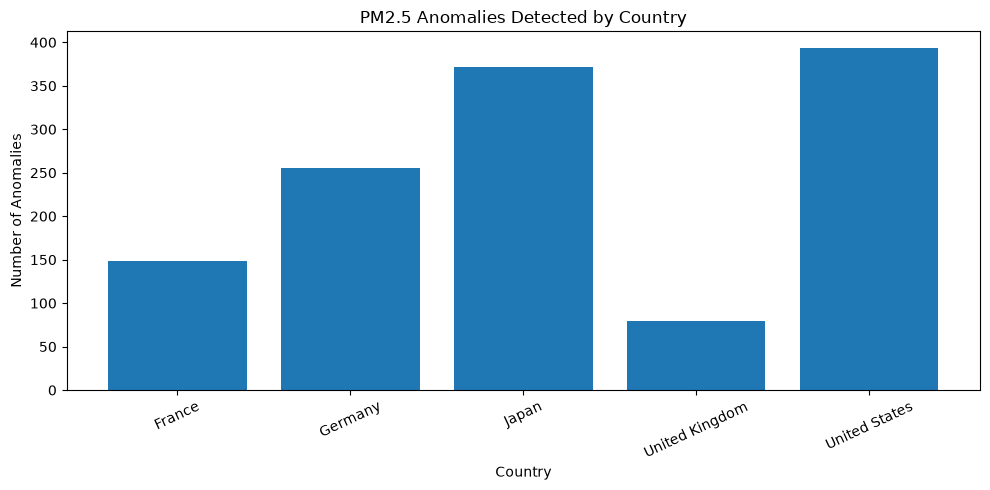

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    country_anomaly_summary["country"],
    country_anomaly_summary["anomalies"]
)

plt.title("PM2.5 Anomalies Detected by Country")
plt.xlabel("Country")
plt.ylabel("Number of Anomalies")
plt.xticks(rotation=25)
plt.tight_layout()

# Save chart
plt.savefig(
    results_folder / "country_anomaly_chart.png",
    dpi=300
)

plt.show()

In [50]:
import matplotlib.pyplot as plt

# Select first 200 test predictions
plot_df = gru_results.sort_values("timestamp").head(200)

plt.figure(figsize=(14, 5))

plt.plot(
    plot_df["timestamp"],
    plot_df["actual"],
    label="Actual PM2.5"
)

plt.plot(
    plot_df["timestamp"],
    plot_df["predicted"],
    label="GRU Predicted PM2.5"
)

plt.title("Actual vs GRU-Predicted PM2.5")
plt.xlabel("Time")
plt.ylabel("PM2.5")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(
    results_folder / "gru_actual_vs_predicted.png",
    dpi=300
)

plt.show()

KeyError: 'actual'

<Figure size 1400x500 with 0 Axes>

In [51]:
print("GRU results columns:")
print(gru_results.columns.tolist())

print("\nFirst 5 rows:")
display(gru_results.head())

GRU results columns:
['timestamp', 'city', 'station_id', 'actual_pm25', 'predicted_pm25']

First 5 rows:


,timestamp,city,station_id,actual_pm25,predicted_pm25
0,2026-09-24 07:00:00+00:00,Spremberg,11770_2935,5.92,5.347131
1,2026-09-24 08:00:00+00:00,Spremberg,11770_2935,6.20,6.111064
2,2026-09-24 09:00:00+00:00,Spremberg,11770_2935,5.37,6.266308
3,2026-09-24 10:00:00+00:00,Spremberg,11770_2935,4.08,5.501575
4,2026-09-24 11:00:00+00:00,Spremberg,11770_2935,3.81,4.612361


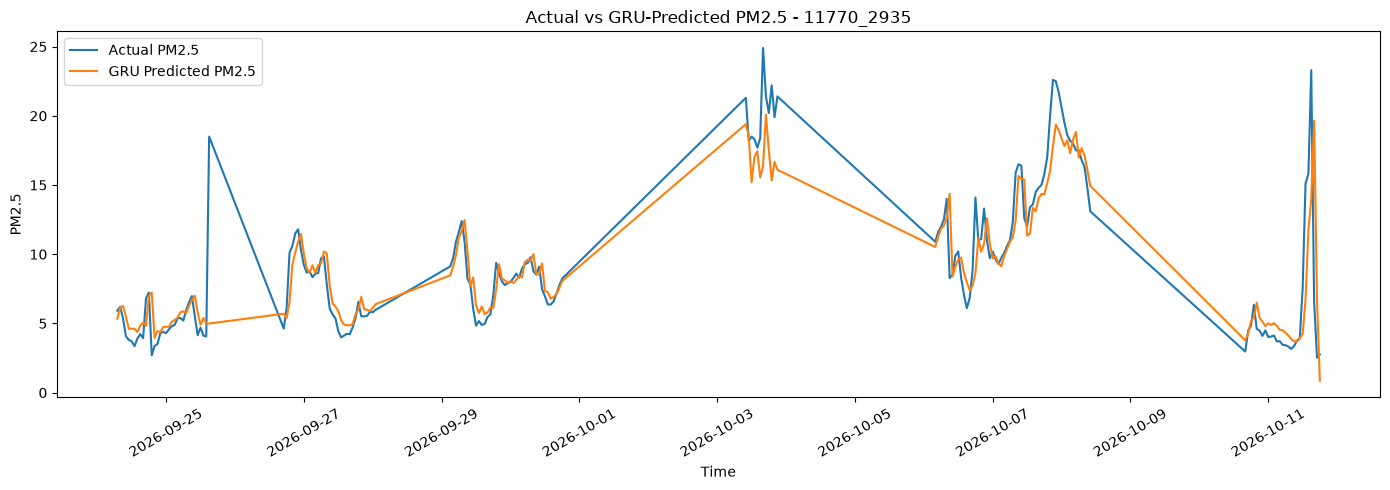

GRU forecast graph saved successfully!


In [52]:
import matplotlib.pyplot as plt

# Select one monitoring station
station_to_plot = gru_results["station_id"].iloc[0]

plot_df = gru_results[
    gru_results["station_id"] == station_to_plot
].sort_values("timestamp").head(200)

# Plot actual vs predicted values
plt.figure(figsize=(14, 5))

plt.plot(
    plot_df["timestamp"],
    plot_df["actual_pm25"],
    label="Actual PM2.5"
)

plt.plot(
    plot_df["timestamp"],
    plot_df["predicted_pm25"],
    label="GRU Predicted PM2.5"
)

plt.title(f"Actual vs GRU-Predicted PM2.5 - {station_to_plot}")
plt.xlabel("Time")
plt.ylabel("PM2.5")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()

# Save graph
plt.savefig(
    results_folder / "gru_actual_vs_predicted.png",
    dpi=300
)

plt.show()

print("GRU forecast graph saved successfully!")